In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [3]:
# 1. LOAD DATA
df = pd.read_csv('data/clean_data.csv')

In [ ]:
# Quick fix for the one remaining missing column
df['num_accounts_120d_past_due'] = df['num_accounts_120d_past_due'].fillna(0)

print("Data Loaded. Shape:", df.shape)

Data Loaded. Shape: (9976, 55)


C:\Users\Yahya\AppData\Local\Temp\ipykernel_9092\3103944802.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='loan_status_binary', data=df, palette='viridis')


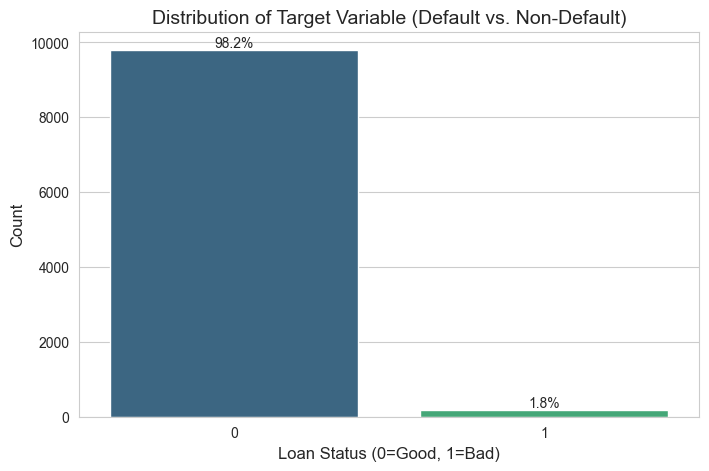

In [ ]:
# ---------------------------------------------------------
# 2. TARGET DISTRIBUTION (The "Imbalance" Figure)
# ---------------------------------------------------------
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='loan_status_binary', data=df, palette='viridis')
plt.title('Distribution of Target Variable (Default vs. Non-Default)', fontsize=14)
plt.xlabel('Loan Status (0=Good, 1=Bad)', fontsize=12)
plt.ylabel('Count', fontsize=12)
# Add percentage labels
total = len(df)
for p in ax.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height()/total)
    x = p.get_x() + p.get_width()/2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')

plt.savefig('target_distribution.png') 
plt.show()

C:\Users\Yahya\AppData\Local\Temp\ipykernel_9092\229703896.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loan_status_binary', y='interest_rate', data=df, ax=axes[0], palette='coolwarm')
C:\Users\Yahya\AppData\Local\Temp\ipykernel_9092\229703896.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loan_status_binary', y='debt_to_income', data=df, ax=axes[1], palette='coolwarm')
C:\Users\Yahya\AppData\Local\Temp\ipykernel_9092\229703896.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='loan_status_binary', y='total_credit_lim

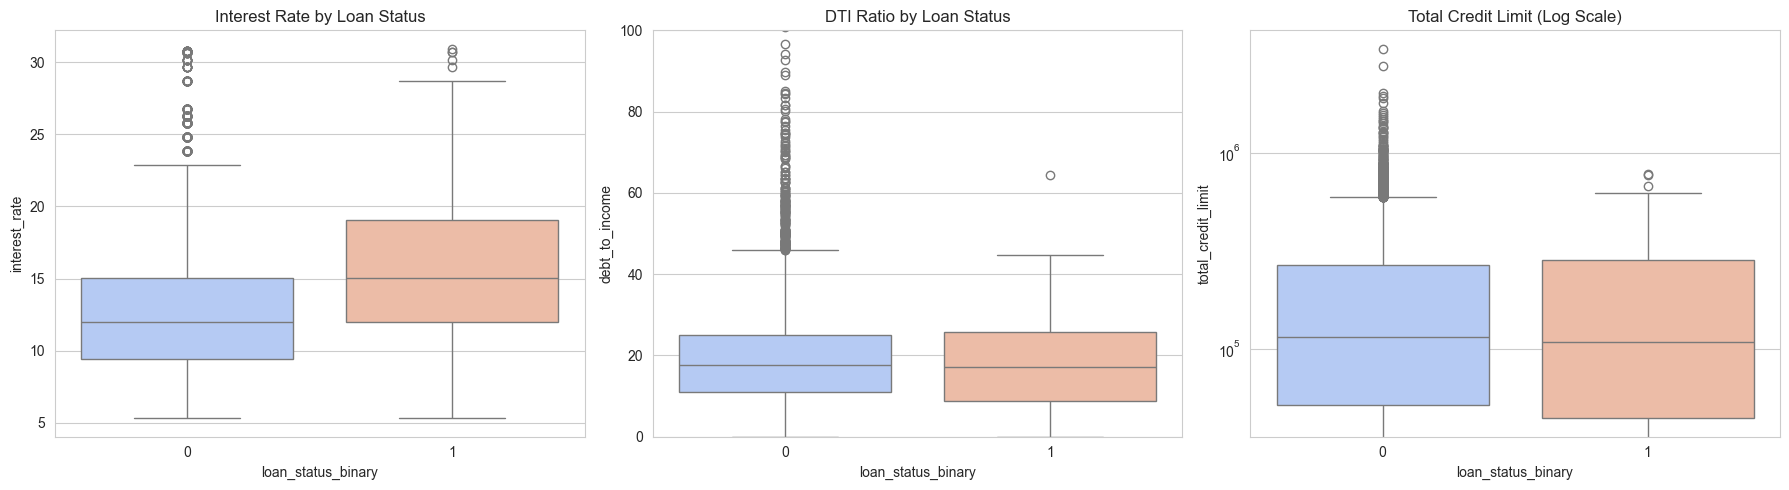

In [ ]:
# ---------------------------------------------------------
# 3. KEY RISK DRIVERS (Boxplots)
# ---------------------------------------------------------
# To show that "Bad" loans have different characteristics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Interest Rate vs Default
sns.boxplot(x='loan_status_binary', y='interest_rate', data=df, ax=axes[0], palette='coolwarm')
axes[0].set_title('Interest Rate by Loan Status')

# Debt-to-Income vs Default (limiting y-axis for readability)
sns.boxplot(x='loan_status_binary', y='debt_to_income', data=df, ax=axes[1], palette='coolwarm')
axes[1].set_ylim(0, 100) # Remove outliers for clearer view
axes[1].set_title('DTI Ratio by Loan Status')

# Total Credit Limit vs Default
sns.boxplot(x='loan_status_binary', y='total_credit_limit', data=df, ax=axes[2], palette='coolwarm')
axes[2].set_yscale('log') # Log scale because limits vary wildly
axes[2].set_title('Total Credit Limit (Log Scale)')

plt.tight_layout()
plt.show()

C:\Users\Yahya\AppData\Local\Temp\ipykernel_9092\3745294105.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='grade', y='loan_status_binary', data=default_rates, palette='Reds')


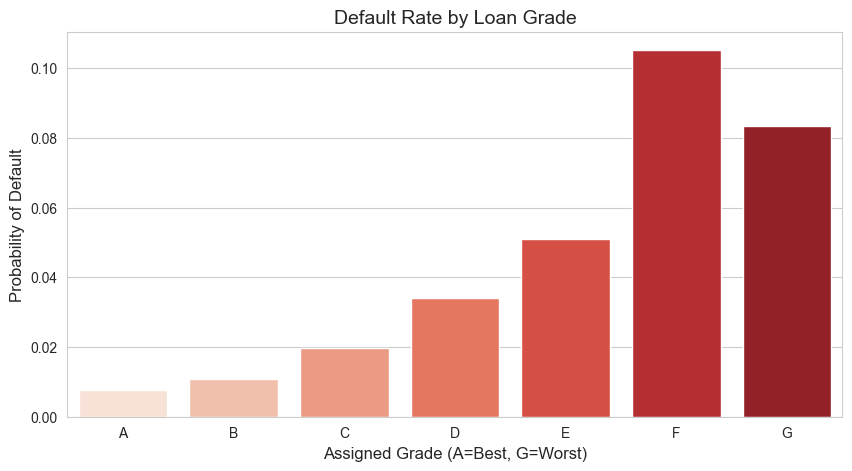

In [9]:
# ---------------------------------------------------------
# 4. DEFAULT RATE BY LOAN GRADE (The "Monotonicity" Check)
# ---------------------------------------------------------
# A good credit model should show higher default rates for lower grades (A -> G)
default_rates = df.groupby('grade')['loan_status_binary'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(x='grade', y='loan_status_binary', data=default_rates, palette='Reds')
plt.title('Default Rate by Loan Grade', fontsize=14)
plt.ylabel('Probability of Default', fontsize=12)
plt.xlabel('Assigned Grade (A=Best, G=Worst)', fontsize=12)
plt.show()

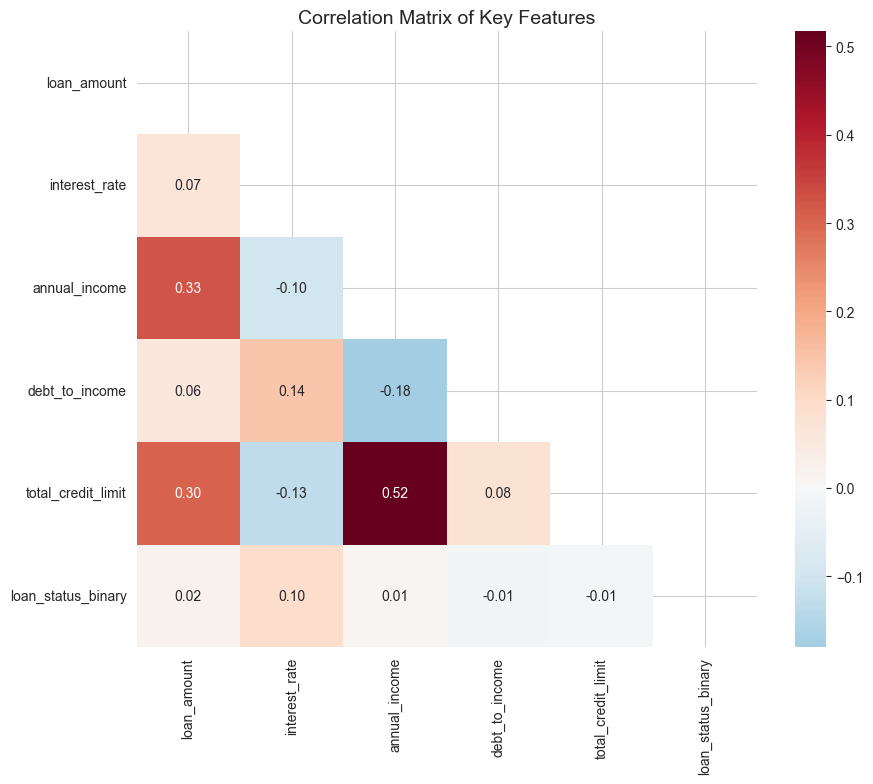


EDA Completed. Check the visual outputs above.


In [ ]:
# ---------------------------------------------------------
# 5. CORRELATION HEATMAP
# ---------------------------------------------------------
# Select meaningful numerical features
corr_cols = ['loan_amount', 'interest_rate', 'annual_income', 'debt_to_income', 
             'fico_score', 'total_credit_limit', 'loan_status_binary']

# Note: 'fico_score' isn't explicitly in the dataset, but 'interest_rate' is a proxy.
# Let's use available columns:
corr_cols = ['loan_amount', 'interest_rate', 'annual_income', 'debt_to_income', 
             'total_credit_limit', 'loan_status_binary']

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(df[corr_cols].corr(), dtype=bool))
sns.heatmap(df[corr_cols].corr(), mask=mask, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('Correlation Matrix of Key Features', fontsize=14)
plt.show()

print("\nEDA Completed..")